In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("cleaned_corpus.csv", index_col = 0, parse_dates = ['approved_date'])
corpus = df['cleaned_content']

[Text(0.5, 1.0, 'RAs per year'), Text(0.5, 0, 'Year'), Text(0, 0.5, 'Count')]

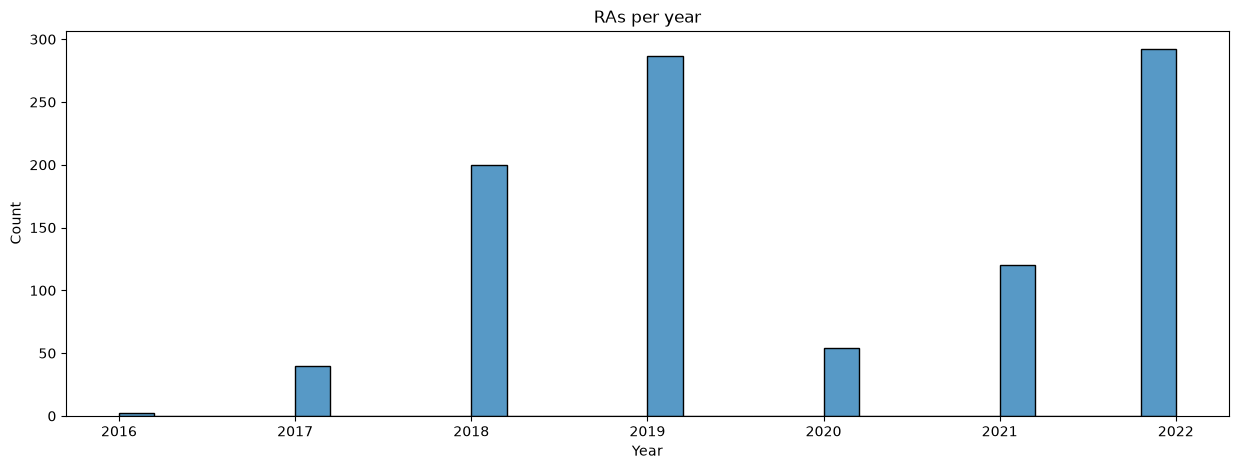

In [3]:
fig, ax = plt.subplots(figsize = (15, 5))
g = sns.histplot(x = 'year', bins = 30, data = df, ax = ax)
g.set(title = 'RAs per year', xlabel = 'Year', ylabel = 'Count')

In [4]:
count_vectorizer = CountVectorizer()
vectorized = count_vectorizer.fit_transform(corpus)

print("Shape of our DTM:", vectorized.shape)

Shape of our DTM: (995, 16026)


In [5]:
dtm = pd.DataFrame(
    vectorized.toarray(),
    columns = count_vectorizer.get_feature_names_out(),
    index = df['basename']
)

In [6]:
def plot_metrics(data, col, title = '', xlabel = ''):
    """Plot metrics with a histogram."""
    fig, ax = plt.subplots(figsize = (15, 5))
    g = sns.histplot(x = col, data = data)
    g.set(title = title, xlabel = xlabel, ylabel = 'Count')

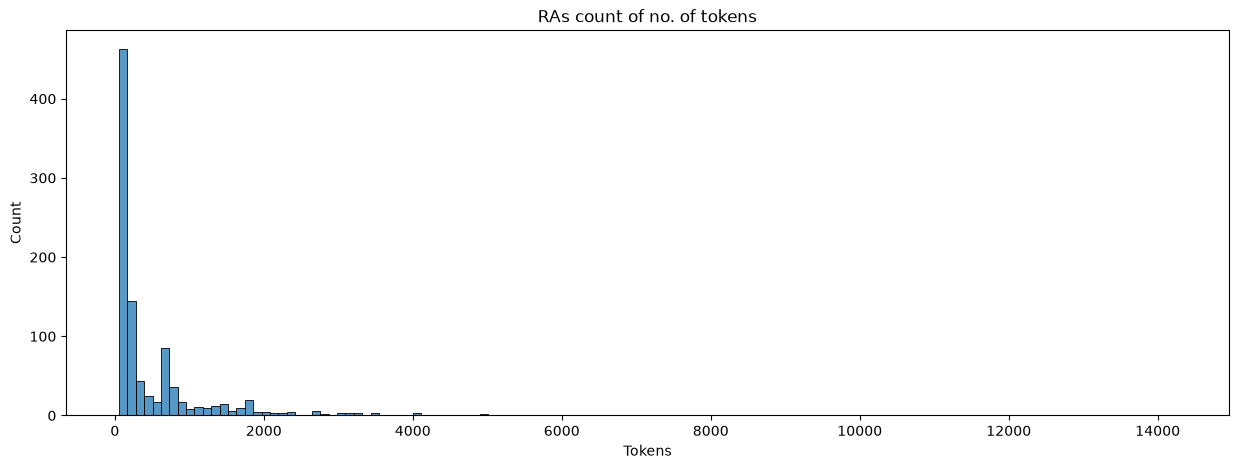

In [7]:
df.loc[:, 'num_tokens'] = dtm.apply(sum, axis = 1).values
plot_metrics(df, 'num_tokens', title = 'RAs count of no. of tokens', xlabel = 'Tokens')

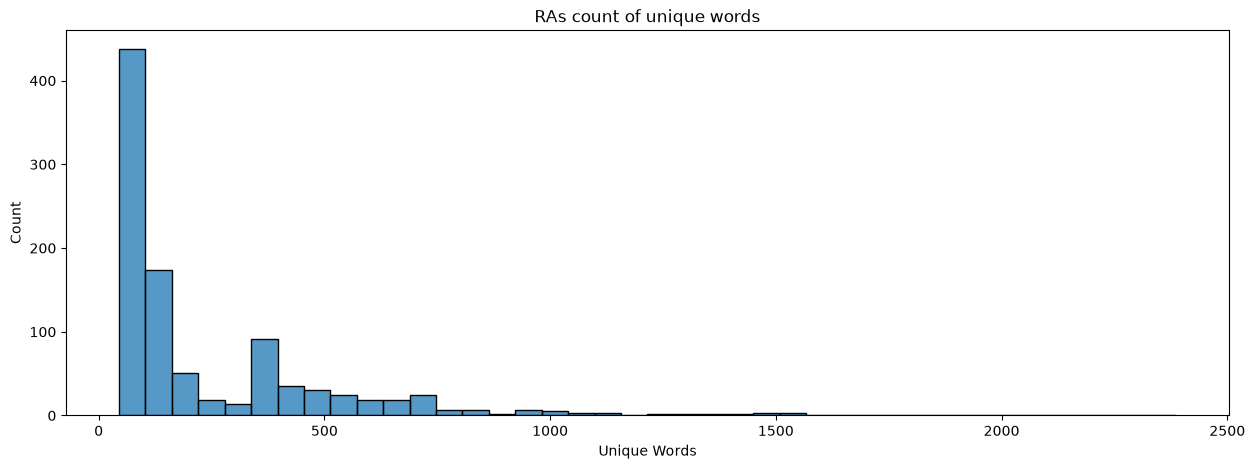

In [8]:
# unique words, or types, in each text. Types correspond to a text's vocabulary
df.loc[:, 'num_types'] = dtm.apply(np.count_nonzero, axis = 1).values
plot_metrics(df, 'num_types', title = 'RAs count of unique words', xlabel = 'Unique Words')

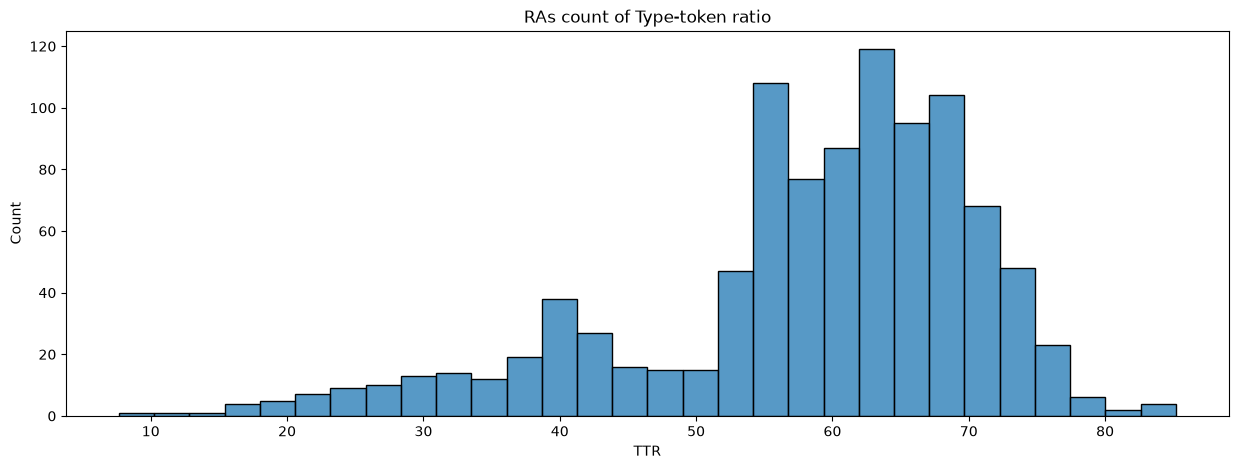

In [9]:
# lexical diversity - type-token ratio (TTR) measures how much the vocabulary of a text varies over its tokens
# to interpret - a text with a TTR of 100 would never repeat a word
df.loc[:, 'TTR'] = (df['num_types'] / df['num_tokens']) * 100
plot_metrics(df, 'TTR', title = 'RAs count of Type-token ratio', xlabel = 'TTR')

In [10]:
# low-med-high summary
def show_examples(data, metric, labels = ['low', 'medium', 'high']):
    cuts = pd.qcut(data[metric], len(labels), labels = labels)
    for label in labels:
        idxes = cuts[cuts==label].index
        ex = data[data.index.isin(idxes)].sample()
        print(f"+ {label}: {ex['basename'].item()} ({ex[metric].item():0.2f})")

for metric in ('num_tokens', 'num_types', 'TTR'):
    print("Examples for", metric)
    show_examples(df, metric)
    print("\n")

Examples for num_tokens
+ low: ra_11007_2018 (99.00)
+ medium: ra_11280_2019 (140.00)
+ high: ra_11542_2021 (740.00)


Examples for num_types
+ low: ra_11852_2022 (80.00)
+ medium: ra_10960_2017 (127.00)
+ high: ra_11352_2019 (354.00)


Examples for TTR
+ low: ra_11229_2019 (42.41)
+ medium: ra_11281_2019 (64.26)
+ high: ra_11488_2020 (66.67)




In [11]:
summed = pd.DataFrame(dtm.sum(), columns = ('count', ))
summed.sort_values('count', ascending = False, inplace = True)
summed.head(5)

,count
section,14321
provide,6906
this_act,6475
service,4864
philippine,4539


In [12]:
summed.tail(5)

,count
yearbook,1
yearareencouragedtointegrate,1
yeara,1
ystemic,1
yyy,1


In [13]:
# hapax legomena (Greek for 'only said once')
hapaxes = summed[summed['count'] == 1]
print(f"{len(hapaxes)} hapaxes ({len(hapaxes) / len(dtm.T) * 100:0.2f}%)")

4990 hapaxes (31.14%)


[Text(0.5, 1.0, 'Term distribution'), Text(0.5, 0, 'Terms'), []]

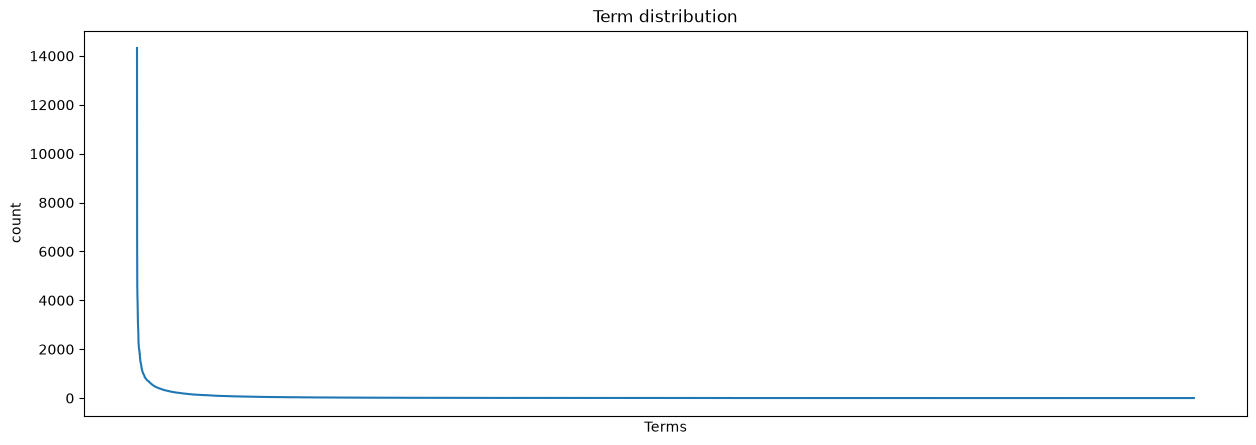

In [14]:
fig, ax = plt.subplots(figsize = (15, 5))
g = sns.lineplot(x = summed.index, y = 'count', data = summed)
g.set(title = 'Term distribution', xlabel = 'Terms', xticks = [])

# still a lot of terms with high-frequency

In [15]:
tfidf_vectorizer = TfidfVectorizer()
vectorized_tfidf = tfidf_vectorizer.fit_transform(corpus)
tfidf = pd.DataFrame(
    vectorized_tfidf.toarray(),
    columns = tfidf_vectorizer.get_feature_names_out(),
    index = df['basename']
)

In [16]:
def counts_vs_tfidf(dtm, tfidf, idx, n_terms = 10):
    """Compare raw document counts with tf-idf scores."""
    c = dtm.loc[idx].nlargest(n_terms)
    t = tfidf.loc[idx].nlargest(n_terms)
    df = pd.DataFrame({
        'count_term': c.index, 'count': c.values,
        'tfidf_term': t.index, 'tfidf': t.values
    })

    return df

for name in df['basename'].sample(3):
    comparison = counts_vs_tfidf(dtm, tfidf, name)
    print("Republic Act:", name)
    display(comparison)

Republic Act: ra_11704_2022


,count_term,count,tfidf_term,tfidf
0,section,7,pjgmrmc,0.588764
1,this_act,5,dr_paulino,0.277828
2,pjgmrmc,4,garcia,0.249530
3,secretary,4,doh,0.191867
4,capacity,3,thousand,0.191266
5,department,3,memorial,0.175260
6,doh,3,capacity,0.167383
7,bed,2,section,0.142892
8,center,2,bed,0.142276
9,dr_paulino,2,cabanatuan,0.138914


Republic Act: ra_11637_2021


,count_term,count,tfidf_term,tfidf
0,franchise,24,grantee,0.484546
1,grantee,24,franchise,0.456610
2,section,17,station,0.283026
3,public,15,public,0.202421
4,station,15,broadcast,0.157555
5,provide,10,congress,0.152799
6,congress,9,ntc,0.147259
7,facility,8,section,0.118086
8,operation,8,provide,0.114340
9,act,7,radio,0.107373


Republic Act: ra_11802_2022


,count_term,count,tfidf_term,tfidf
0,campus,18,pup,0.588339
1,pup,16,alfonso,0.556225
2,alfonso,13,campus,0.414689
3,section,13,maragondon,0.178701
4,this_act,10,polytechnic,0.117374
5,philippine,7,annex,0.116541
6,provision,7,cavite,0.092267
7,act,4,section,0.085344
8,annex,4,university,0.084117
9,board,4,this_act,0.067521


In [17]:
ra_11493_2020 = counts_vs_tfidf(dtm, tfidf, 'ra_11493_2020', 15)
ra_11493_2020.loc[:, 'corpus_count'] = dtm[ra_11493_2020['count_term']].mean().values
ra_11493_2020.loc[:, 'corpus_tfidf'] = tfidf[ra_11493_2020['tfidf_term']].mean().values

cols = ['count_term', 'count', 'corpus_count', 'tfidf_term', 'tfidf', 'corpus_tfidf']
ra_11493_2020 = ra_11493_2020[cols]
ra_11493_2020

,count_term,count,corpus_count,tfidf_term,tfidf,corpus_tfidf
0,grantee,28,4.072362,grantee,0.514276,0.070686
1,franchise,23,3.100503,franchise,0.398085,0.051579
2,public,20,4.481407,public,0.245532,0.039877
3,section,19,14.392965,station,0.240313,0.032094
4,provide,15,6.940704,ntc,0.191380,0.019044
5,station,14,1.882412,broadcast,0.184286,0.016851
6,ntc,10,0.993970,provide,0.156029,0.036413
7,broadcast,9,0.769849,bicol,0.141580,0.001503
8,facility,9,2.253266,congress,0.123561,0.018836
9,operation,9,2.095477,section,0.120065,0.086954


In [18]:
tfidf.to_csv('tfidf_scores.csv')